# Question 1

### 1.1

In [1]:
#Importing Libraries
import json
import re
import pandas as pd
import numpy as np

In [2]:
#Loading json file
with open("research_abstracts.json", "r", encoding = "utf-8") as e:
    raw_data = json.load(e)

data = pd.DataFrame(raw_data)
print("Shape:",data.shape)
data.head()

Shape: (1138, 3)


,DOI,Abstract,Label
0,10.1155/2021/1071145,Forward-looking forecasting of the inflation r...,ai
1,10.1007/s43546-022-00384-2,Our study examined the disaggregation of infla...,ai
2,10.1002/for.2667,This paper develops a dynamic factor model tha...,classical
3,10.1007/s42973-021-00091-x,"In this paper, I use a simple SIR Macro model ...",classical
4,10.1007/s40258-012-0003-z,BackgroundGame theory is useful for identifyin...,classical


In [3]:
#Searching for the number of null values, and duplicates in DOI and Abstract
print("Missing Values:\n", data.isnull().sum())
print("Duplicate DOI:", data["DOI"].duplicated().sum())
print("Dupplicate Abstract:", data["Abstract"].duplicated().sum())
print("Label distribution:", data["Label"].value_counts())

Missing Values:
 DOI         4
Abstract    0
Label       0
dtype: int64
Duplicate DOI: 3
Dupplicate Abstract: 13
Label distribution: Label
classical    900
ai           238
Name: count, dtype: int64


In [4]:
data = data.drop_duplicates(subset = "Abstract").reset_index(drop = True)
data = data.dropna(subset=["DOI"])
print(data.shape)
data.head()

(1123, 3)


,DOI,Abstract,Label
0,10.1155/2021/1071145,Forward-looking forecasting of the inflation r...,ai
1,10.1007/s43546-022-00384-2,Our study examined the disaggregation of infla...,ai
2,10.1002/for.2667,This paper develops a dynamic factor model tha...,classical
3,10.1007/s42973-021-00091-x,"In this paper, I use a simple SIR Macro model ...",classical
4,10.1007/s40258-012-0003-z,BackgroundGame theory is useful for identifyin...,classical


In [5]:
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

In [6]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def denoise_text(text):
    #for lowercase, remove URLs, keep letters only, normalise whitespaces
    #tokenise, lemmatise and stop word
    text = text.lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    tokens = word_tokenize(text)
    tokens = [lemmatizer.lemmatize(t) for t in tokens if t not in stop_words and len(t) > 2]
    return " ".join(tokens)

data["Clean_Abstract"] = data["Abstract"].apply(denoise_text)
data[["Abstract", "Clean_Abstract"]].head(5)

,Abstract,Clean_Abstract
0,Forward-looking forecasting of the inflation r...,forward looking forecasting inflation rate cou...
1,Our study examined the disaggregation of infla...,study examined disaggregation inflation compon...
2,This paper develops a dynamic factor model tha...,paper develops dynamic factor model us euro ar...
3,"In this paper, I use a simple SIR Macro model ...",paper use simple sir macro model examine japan...
4,BackgroundGame theory is useful for identifyin...,backgroundgame theory useful identifying condi...


### 1.2

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

X_text = data["Clean_Abstract"]
y = data["Label"]

tfidf = TfidfVectorizer(max_features = 3000, ngram_range = (1, 2), min_df = 2)
X = tfidf.fit_transform(X_text)

print("TF-IDF matrix shape:", X.shape)
print("Sample vocabulary:", list(tfidf.get_feature_names_out()[:12]))

TF-IDF matrix shape: (1123, 3000)
Sample vocabulary: ['ability', 'able', 'absence', 'absolute', 'absolute error', 'absolute percentage', 'abstract', 'academic', 'access', 'accommodate', 'accordance', 'according']


### 1.3

In [8]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2,
                                                    random_state = 42, stratify = y)

print("Train size:", X_train.shape[0], " Test size:", X_test.shape[0])
print("\nTrain label distribution:\n", y_train.value_counts())
print("\nTest Label distribution:\n", y_test.value_counts())

Train size: 898  Test size: 225

Train label distribution:
 Label
classical    712
ai           186
Name: count, dtype: int64

Test Label distribution:
 Label
classical    178
ai            47
Name: count, dtype: int64


### Baseline Model

In [9]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

clf = MultinomialNB()
clf.fit(X_train, y_train)

train_pred = clf.predict(X_train)
test_pred = clf.predict(X_test)

train_acc = accuracy_score(y_train, train_pred)
test_acc = accuracy_score(y_test, test_pred)

print(f"Training Accuracy: {train_acc:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

Training Accuracy: 0.9109
Test Accuracy: 0.8756


### Performance report

In [10]:
print("Classification report (test set):\n")
print(classification_report(y_test, test_pred))

print("Confusion Matrix (rows = actual, cols = predicted, order = [ai, classical]):")
print(confusion_matrix(y_test, test_pred, labels = ["ai", "classical"]))

Classification report (test set):

              precision    recall  f1-score   support

          ai       0.95      0.43      0.59        47
   classical       0.87      0.99      0.93       178

    accuracy                           0.88       225
   macro avg       0.91      0.71      0.76       225
weighted avg       0.89      0.88      0.86       225

Confusion Matrix (rows = actual, cols = predicted, order = [ai, classical]):
[[ 20  27]
 [  1 177]]


### Comment

The training accuracy is 91.03% and the test accuracy is 87.56% which are close to each other just3.47% apart. This is a small gap so the model is not  badly overfitting as it has learnt genuine patterns in the vocabulary rather than memorising the training abstracts.

The accuracies can be misleading as we see a test accuracy of 87.56% which looks strong but the dataset is imbalanced with 900 classical records vs 238 that are ai which is 79% as to 21% record wise, the classifier would already score 79% accuracy because classical holds 79% of the records, so the 87.56% is a real but modest improvement over that naive baseline.

Recall for classical is 99% which is 177/178 correctly found, but the recall for ai is only 43% which is 20/47 correctly found. The confusion matrix shows 27 ai abstracts were misclassified as classical meaning the model is baised towards the majority class

# Question 2

### 2.1

In [11]:
#Logistic Regression
from sklearn.linear_model import LogisticRegression

LR_Model = LogisticRegression(max_iter = 1000, random_state = 42)
LR_Model.fit(X_train, y_train)

y_pred_test = LR_Model.predict(X_test)
print("Classification Report:\n", classification_report(y_test, y_pred_test))
print("Confusion Matrix:\n", confusion_matrix(y_true = y_test, y_pred = y_pred_test))
print("Logistic Regression Test Accuracy: ", accuracy_score(y_test, y_pred_test))

Classification Report:
               precision    recall  f1-score   support

          ai       1.00      0.38      0.55        47
   classical       0.86      1.00      0.92       178

    accuracy                           0.87       225
   macro avg       0.93      0.69      0.74       225
weighted avg       0.89      0.87      0.85       225

Confusion Matrix:
 [[ 18  29]
 [  0 178]]
Logistic Regression Test Accuracy:  0.8711111111111111


In [12]:
#Linear SVM
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score


LinearSVM_Model = LinearSVC(random_state = 42)
LinearSVM_Model.fit(X_train, y_train)

y_pred_test = LinearSVM_Model.predict(X_test)
print("Classification Report:\n", classification_report(y_test, y_pred_test))
print("Confusion Matrix:\n", confusion_matrix(y_true = y_test, y_pred = y_pred_test))
print("Linear SVM Test Accuracy: ", accuracy_score(y_test, y_pred_test))

Classification Report:
               precision    recall  f1-score   support

          ai       0.89      0.66      0.76        47
   classical       0.92      0.98      0.95       178

    accuracy                           0.91       225
   macro avg       0.90      0.82      0.85       225
weighted avg       0.91      0.91      0.91       225

Confusion Matrix:
 [[ 31  16]
 [  4 174]]
Linear SVM Test Accuracy:  0.9111111111111111


In [13]:
#Random Forest Model
from sklearn.ensemble import RandomForestClassifier

RF_Model = RandomForestClassifier(n_estimators = 300, random_state = 42)
RF_Model.fit(X_train, y_train)

y_pred_test = RF_Model.predict(X_test)
print("Classification Report:\n", classification_report(y_test, y_pred_test))
print("Confusion Matrix:\n", confusion_matrix(y_true = y_test, y_pred = y_pred_test))
print("Random Forest Test Accuracy: ", accuracy_score(y_test, y_pred_test))

Classification Report:
               precision    recall  f1-score   support

          ai       1.00      0.68      0.81        47
   classical       0.92      1.00      0.96       178

    accuracy                           0.93       225
   macro avg       0.96      0.84      0.88       225
weighted avg       0.94      0.93      0.93       225

Confusion Matrix:
 [[ 32  15]
 [  0 178]]
Random Forest Test Accuracy:  0.9333333333333333


In [14]:
#XGBoost Model
from sklearn.ensemble import GradientBoostingClassifier

XGB_Model = GradientBoostingClassifier(random_state = 42)
XGB_Model.fit(X_train, y_train)

y_pred_test = XGB_Model.predict(X_test)
print("Classification Report:\n", classification_report(y_test, y_pred_test))
print("Confusion Matrix:\n", confusion_matrix(y_true = y_test, y_pred = y_pred_test))
print("XGBoost Test Accuracy: ", accuracy_score(y_test, y_pred_test))

Classification Report:
               precision    recall  f1-score   support

          ai       0.81      0.74      0.78        47
   classical       0.93      0.96      0.94       178

    accuracy                           0.91       225
   macro avg       0.87      0.85      0.86       225
weighted avg       0.91      0.91      0.91       225

Confusion Matrix:
 [[ 35  12]
 [  8 170]]
XGBoost Test Accuracy:  0.9111111111111111


### Result



Three of the four models beat the baseline model. XGBoost had a test accuracy of 91%, Macro F1 of 86% and a ai recall of 74%. Random Forest had test accuracy of 93%, Macro F1 of 88% and ai recall of 68%. Linear SVM had a Test accuracy of 91%, Macro F1 of 85% and a ai recall of 66%.

Leaving Logistic Regression being the worst of the four models and even worser than the baseline as it got a test accuracy of 87,1% whilst the baseline test accuracy was 87,5%, it also performed below the baseline numbers on Macro F1 and ai recall as the baseline got Macro F1 of 76% and ai recall of 43% whilse Logistic Regression got Macro F1 of 75% and ai recall of 38%.

So the overall best Model is Random Forest as the model has a Test accuracy of 93% and a Macro F1 of 88%.

### 2.2

In [15]:
from sklearn.utils import resample
from collections import Counter
import matplotlib.pyplot as plt

print("Imbalanced class distribution:", Counter(y_train))
X_data = pd.DataFrame(X_train.toarray())
y_series = pd.Series(np.asarray(y_train), name = "y").reset_index(drop = True)
bal_data = pd.concat([X_data, y_series], axis = 1)
max_size = bal_data["y"].value_counts().max()
bal_upsampled = pd.concat([ resample(bal_data[bal_data["y"] == cls], replace = True,
                                     n_samples = max_size, random_state = 42)
                            for cls in bal_data["y"].unique()])

bal_upsampled = bal_upsampled.sample(frac = 1, random_state = 42).reset_index(drop = True)

X_balanced = bal_upsampled.drop(columns = ["y"]).values
y_balanced = bal_upsampled["y"]
print("Balanced class distribution:", Counter(y_balanced))

Imbalanced class distribution: Counter({'classical': 712, 'ai': 186})
Balanced class distribution: Counter({'ai': 712, 'classical': 712})


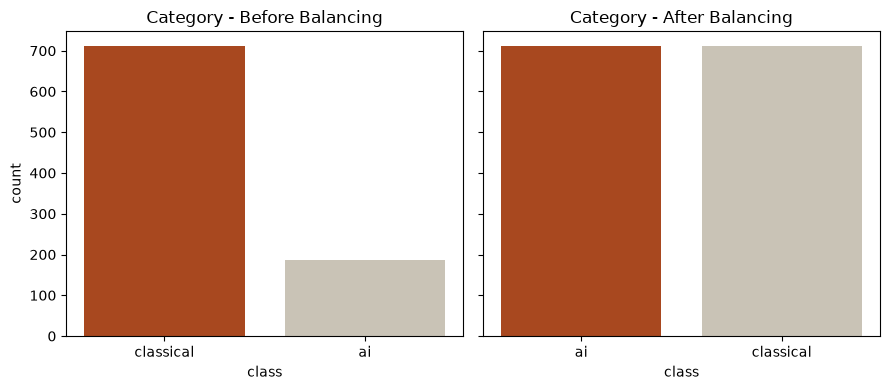

In [16]:
fig, axes = plt.subplots(1, 2, figsize = (9, 4), sharey = True)

count_before = pd.Series(y_train).value_counts()
count_after = pd.Series(y_balanced).value_counts()

axes[0].bar(count_before.index.astype(str), count_before.values, color = ["#a8481f", "#c9c3b6"])
axes[0].set_title("Category - Before Balancing")
axes[0].set_xlabel("class")
axes[0].set_ylabel("count")

axes[1].bar(count_after.index.astype(str), count_after.values, color = ["#a8481f", "#c9c3b6"])
axes[1].set_title("Category - After Balancing")
axes[1].set_xlabel("class")
plt.tight_layout()
plt.show()

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

type_labels = ["ai", "classical"]

max_epoch = 300
log_reg_clf = LogisticRegression(max_iter = max_epoch,
                                 random_state = 42)

log_reg_clf.fit(X_balanced, y_balanced)
y_pred_train_baseline = log_reg_clf.predict(X_train)
print("Training set\n", classification_report(y_train, y_pred_train_baseline, target_names = type_labels))
y_pred_test_baseline = log_reg_clf.predict(X_test)
print("Test set\n", classification_report(y_test, y_pred_test_baseline, target_names = type_labels))

Training set
               precision    recall  f1-score   support

          ai       0.88      0.95      0.91       186
   classical       0.99      0.97      0.98       712

    accuracy                           0.96       898
   macro avg       0.94      0.96      0.95       898
weighted avg       0.96      0.96      0.96       898

Test set
               precision    recall  f1-score   support

          ai       0.72      0.77      0.74        47
   classical       0.94      0.92      0.93       178

    accuracy                           0.89       225
   macro avg       0.83      0.84      0.84       225
weighted avg       0.89      0.89      0.89       225



After applying the upsampling, the model's performance improved, the test accuracy increased 87% to 89%, while the AI class F1-score improved from 0.55 to 0.74. Most notably, the recall for AI abstracts increased from 0.38 to 0.77, indicating that the model is now able to identify the majority of relevant AI papers. ALthough AI precision decreased to 0.72, this trade off is acceptable for the Researchly application where retrieving relevant research articles is more important than missing them and overall upsampling effectively relieved the class imbalance and produduced a more balanced classifier that performs well on both AI and Classical research abstracts.

### 2.3

In [18]:
import joblib
from sklearn.ensemble import RandomForestClassifier

#Train best model
RF_Model = RandomForestClassifier(n_estimators = 300, random_state = 42)
RF_Model.fit(X_train, y_train)

#Save model
joblib.dump(RF_Model, "RF_Model.pkl")
joblib.dump(tfidf, "vectorizer.pkl")

['vectorizer.pkl']

In [19]:
%%writefile app.py
import streamlit as st
import joblib

#Load model and vectorizer
model = joblib.load("RF_Model.pkl")
vectorizer = joblib.load("vectorizer.pkl")

st.title("Researchly Research Abstract Classifier")
st.write(""" This app classifiees research abstracts as either AI-related or classical research.""")

abstract = st.text_area("Enter research abstract:",
                        height = 200)

if st.button("Classify Abstract"):
    if abstract.strip() == "":
        st.warning("Please enter an abstract.")
    else:
        #Convert text into numerical features
        abstract_vector = vectorizer.transform([abstract])

        #predict class
        prediction = model.predict(abstract_vector)[0]

        st.subheader("Prediction")
        st.success(f"The abstract is classified as: {prediction}")

Overwriting app.py


![Streamlit web-interface](Streamlit_Web_interface.png)

In [20]:
import ipywidgets as widgets
from IPython.display import display, HTML

Label_selector = {"ai": "artificial intelligence", "classical": "classical research"}

def classify_abstract(raw_text):
    clean = denoise_text(raw_text)
    vec = tfidf.transform([clean])
    pred = RF_Model.predict(vec)[0]
    proba = RF_Model.predict_proba(vec)[0]
    class_idx = list(RF_Model.classes_).index(pred)
    confidence = proba[class_idx]
    return pred, Label_selector[pred], confidence

#Interface
title = widgets.HTML(
    "<h1 style = 'font-weight:800'>Researchly Research Abstract Classifier</h1>"
    "<p>This app classifies research abstracts as either AI-related or classical research.</p>")

label = widgets.HTML("<b>Enter research abstract</b>")
text_area = widgets.Textarea(
    placeholder = "Write or paster a research abstract here...",
    layout = widgets.Layout(width = "100%", height = "160px"))

classify_button = widgets.Button(description = "Classify Abstract")
output = widgets.Output()

def on_classify_click(b):
    with output:
        output.clear_output()
        text = text_area.value.strip()
        if not text:
            display(HTML("<p>Please enter an abstract to classifiy.</p>"))
            return
        pred, disp_label, confidence = classify_abstract(text)
        colour = "#15803d" if pred == "ai" else "#92400e"
        bg = "#dcfce7" if pred == "ai" else "#fef3c7"
        display(HTML(
            f"<h2 style = 'font-weight:800'>Prediction</h2>"
            f"<div style = 'background:{bg}; color:{colour};"
            f"border-radius: 10px; font-weight:500'> The abstract is classified as: {disp_label}</div>"))

classify_button.on_click(on_classify_click)
display(widgets.VBox([title, label, text_area, classify_button, output]))

# Question 3

#### 3.1

In [21]:
import os

CORPUS_DIR = "research_corpus"

records = []
for fname in sorted(os.listdir(CORPUS_DIR)):
    if fname.endswith(".txt"):
        with open(os.path.join(CORPUS_DIR, fname), "r", encoding = "utf-8") as f:
            content = f.read()
            records.append({"filename": fname, "content": content})

articles_data = pd.DataFrame(records).sort_values("filename").reset_index(drop = True)
print("Shape:", articles_data.shape)
articles_data[["filename"]].assign(characters = articles_data["content"].str.len())

Shape: (5, 2)


,filename,characters
0,research_1.txt,38160
1,research_2.txt,16104
2,research_3.txt,26154
3,research_4.txt,38950
4,research_5.txt,26831


In [22]:
articles_data.head()

,filename,content
0,research_1.txt,The purposes of this article are to position m...
1,research_2.txt,"Now I see it, now I don’t:\nresearcher’s posit..."
2,research_3.txt,DEVELOPMENTAL RESEARCH: STUDIES OF\nINSTRUCTIO...
3,research_4.txt,Abstract\nCronbach’s alpha is a statistic comm...
4,research_5.txt,Denzin’s Paradigm Shift: Revisiting Triangulat...


### 3.2

In [23]:
for _, row in articles_data.iterrows():
    text = row["content"]
    probe = text[:300]
    second_occurrence = text.find(probe, 300)
    flag = "DUPLICATED" if second_occurrence != -1 else "ok"
    print(f"{row['filename']:16s} len = {len(text):6d} {flag}")

research_1.txt   len =  38160 DUPLICATED
research_2.txt   len =  16104 ok
research_3.txt   len =  26154 ok
research_4.txt   len =  38950 ok
research_5.txt   len =  26831 ok


In [24]:
def remove_duplicated_body(text):
    """Detect an exact first-half/second half repeat and keep only one copy"""
    n = len(text)
    half = n // 2
    first_half, second_half = text[:half], text[half:]
    if len(first_half)> 500 and first_half.strip() == second_half.strip()[:len(first_half.strip())]:
        return first_half
    return text

def denoise_for_sentences(text):
    t = remove_duplicated_body(text)
    t = t.replace("\r", " ")
    t = re.sub(r"-\n", "", t)
    t = re.sub(r"\n+", " ", t)
    t = re.sub(r"\s+", " ", t).strip()
    return t

def denoise_text_articles(text):
    t = denoise_for_sentences(text)
    t = t.lower()
    t = re.sub(r"http\S+|www\.\S+", " ", t) 
    t = re.sub(r"\([^)]*\d{4}[^)]*\)", " ", t)
    t = re.sub(r"\b[a-z]+\s*&\s*[a-z]+,?\s*\d{4}\b", " ", t)
    t = re.sub(r"\bp{1,2}\.\s*\d+\b", " ", t)
    t = re.sub("[^a-z\s]", " ", t)
    t = re.sub(r"\s+", " ", t).strip()
    tokens = word_tokenize(t)
    tokens = [lemmatizer.lemmatize(tok) 
              for tok in tokens 
              if tok not in stop_words and len(tok) > 2]
    return " ".join(tokens)

articles_data["Clean_Sentences"] = articles_data["content"].apply(denoise_for_sentences)
articles_data["Clean_Content"] = articles_data["content"].apply(denoise_text_articles)

print("Characters before vs After:")
for _, row in articles_data.iterrows():
    print(f"{row['filename']:16s} raw = {len(row['content']):6d} clean_sentences = {len(row['Clean_Sentences']):6d}")

Characters before vs After:
research_1.txt   raw =  38160 clean_sentences =  19079
research_2.txt   raw =  16104 clean_sentences =  16104
research_3.txt   raw =  26154 clean_sentences =  26154
research_4.txt   raw =  38950 clean_sentences =  38897
research_5.txt   raw =  26831 clean_sentences =  26830


### 3.3

In [25]:
from nltk.tokenize import sent_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer

def freq_based_summarize(clean_sentence_text, n_sentences = 5):
    sentences = sent_tokenize(clean_sentence_text)
    sentences = [s.strip() for s in sentences 
                 if len(s.split()) >= 6]
    n_sentences = min(n_sentences, len(sentences))

    vec = TfidfVectorizer(stop_words = "english")
    tfidf_matrix = vec.fit_transform(sentences)
    nnz_per_row = np.diff(tfidf_matrix.indptr)
    nnz_per_row[nnz_per_row == 0] = 1
    sentence_scores = np.asarray(tfidf_matrix.sum(axis = 1)).ravel() / nnz_per_row

    ranked = sorted(((sentence_scores[i], i, s) 
                     for i, s in enumerate(sentences)), reverse = True)
    top = sorted(ranked[:n_sentences], key = lambda x: x[1])
    summary = " ".join(s for _, _, s in top)
    return summary, sentences, sentence_scores, ranked

first_row = articles_data.iloc[0]
summary, sentences, scores, ranked = freq_based_summarize(first_row["Clean_Sentences"], n_sentences = 5)
print("Article:", first_row["filename"], " | total candicate sentences:", len(sentences))
print()
print("Frequency-based (TF-IDF) summary (top 5 sentences): \n")
print(summary)

Article: research_1.txt  | total candicate sentences: 76

Frequency-based (TF-IDF) summary (top 5 sentences): 

Further, they contend that the observer is separate from the entities that are subject to observation. Quantitative purists maintain that social science inquiry should be objective. We will try to clarify the most important issues in the remainder of this article. There are several interesting myths that appear to be held by some purists. Qualitative researchers also are not immune from constructive criticism.


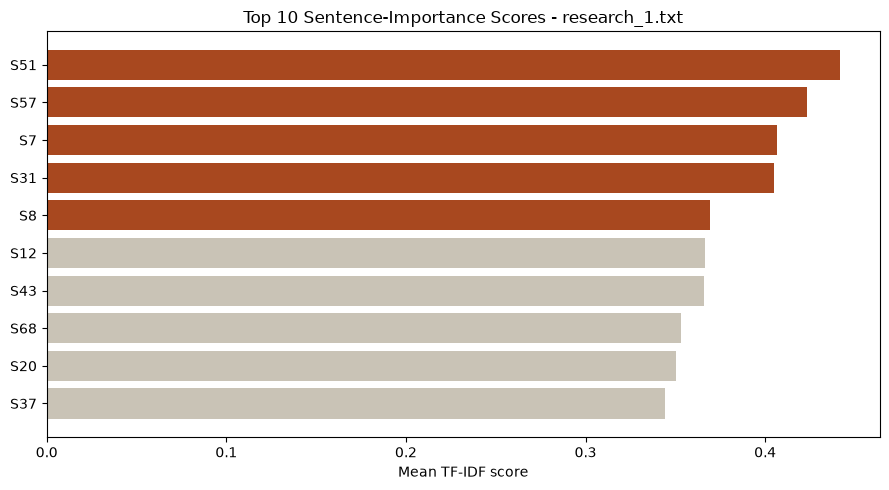

In [26]:
top10 = sorted(((scores[i], i, s) for i, s in enumerate(sentences)), reverse = True)[:10]
selected_idx = {idx for _, idx, _ in sorted(ranked[:5], key = lambda x: x[1])}
labels = [f"S{idx + 1}" for _, idx, _ in top10]
values = [sc for sc, _, _ in top10]
colors = ["#a8481f" if idx in selected_idx else "#c9c3b6" for _, idx, _ in top10]

fig, ax = plt.subplots(figsize = (9, 5))
ax.barh(labels[::-1], values[::-1], color = colors[::-1])
ax.set_xlabel("Mean TF-IDF score")
ax.set_title(f"Top 10 Sentence-Importance Scores - {first_row['filename']}")
plt.tight_layout()
plt.show()

### 3.4

In [27]:
import networkx as nx
from sklearn.metrics.pairwise import cosine_similarity

remaining_data = articles_data.iloc[1:].reset_index(drop = True)

def textrank_aggregate_summarize(data, text_col = "Clean_Sentences", n_sentences = 8, min_words = 6):
    pool = []
    for _, row in data.iterrows():
        for s in sent_tokenize(row[text_col]):
            s = s.strip()
            if len(s.split()) >= min_words:
                pool.append((row["filename"], s))

    sentences = [s for _, s in pool]
    sources = [f for f, _ in pool]
    n_sentences = min(n_sentences, len(sentences))

    vec = TfidfVectorizer(stop_words = "english")
    sent_vectors = vec.fit_transform(sentences)
    sim_matrix = cosine_similarity(sent_vectors)
    np.fill_diagonal(sim_matrix, 0)

    graph = nx.from_numpy_array(sim_matrix)
    scores = nx.pagerank(graph)

    ranked = sorted(((scores[i], i, s) for i, s in enumerate(sentences)), reverse = True)
    top = sorted(ranked[:n_sentences], key = lambda x: x[1])
    summary = " ".join(s for _, _, s in top)
    return summary, sentences, sources, scores, ranked

summary_34, sentences_34, sources_34, score_34, ranked_34 = textrank_aggregate_summarize(remaining_data, n_sentences = 8)
print("Articles summarized as an aggregate:", remaining_data["filename"].tolist())
print("Total candidate sentences pooled:", len(sentences_34))
print()
print("Text Rank aggregate summary (Top 8 sentences, research 2, research 3, research 4, research 5):\n")
print(summary_34)

Articles summarized as an aggregate: ['research_2.txt', 'research_3.txt', 'research_4.txt', 'research_5.txt']
Total candidate sentences pooled: 559

Text Rank aggregate summary (Top 8 sentences, research 2, research 3, research 4, research 5):

In its simplest form, developmental research can be either  the study of the process and impact of specific instructional design and development efforts; or  a situation in which someone is performing instructional design, development, or evaluation activities and studying the process at the same time; or  the study of the instructional design, development, and evaluation process as a whole or of particular process components. The purposes of this chapter are to  explore the nature and background of developmental research;  describe the major types of developmental research by examining a range of representative projects;  analyze the methodological approaches used in the various types of developmental research;  describe the issues, find

In [28]:
selected_idx_34 = sorted(ranked_34[:8], key = lambda x: x[1])
for score, idx, s in selected_idx_34:
    print(f"[{sources_34[idx]}] (score = {score:.4f})")
    print(" ", s)
    print()

[research_3.txt] (score = 0.0043)
  In its simplest form, developmental research can be either  the study of the process and impact of specific instructional design and development efforts; or  a situation in which someone is performing instructional design, development, or evaluation activities and studying the process at the same time; or  the study of the instructional design, development, and evaluation process as a whole or of particular process components.

[research_3.txt] (score = 0.0034)
  The purposes of this chapter are to  explore the nature and background of developmental research;  describe the major types of developmental research by examining a range of representative projects;  analyze the methodological approaches used in the various types of developmental research;  describe the issues, findings, and trends in recent developmental research; and  discuss the future of this type of research in our field.

[research_3.txt] (score = 0.0034)
  A Summary of the Two

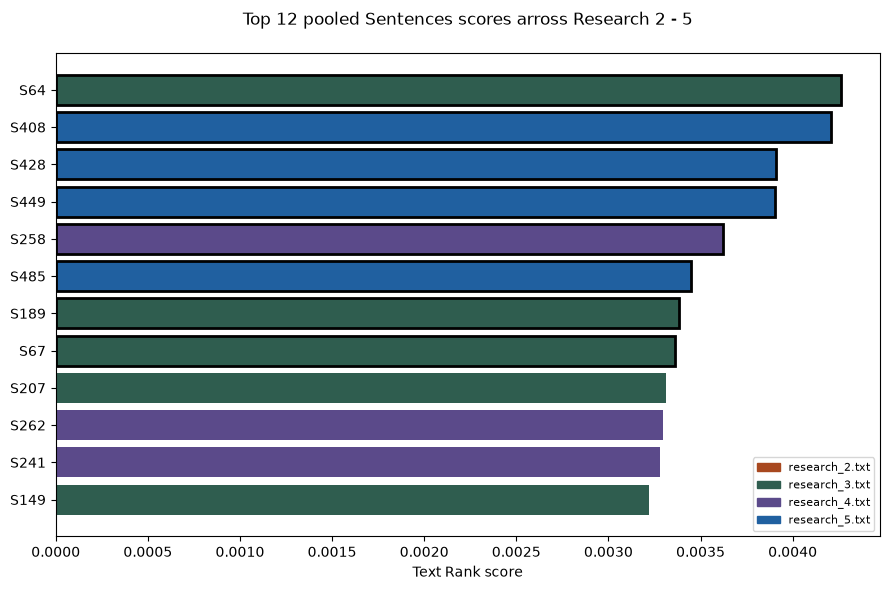

In [29]:
top12_34 = ranked_34[:12]
selected_idx_set_34 = {idx for _, idx, _ in selected_idx_34}
article_order_34 = remaining_data["filename"].tolist()
palette_34 = {f: c for f, c in zip(article_order_34, ["#a8481f", "#2f5d4f", "#5b4a8a", "#2060a0"])}

labels_34 = [f"S{idx}" for _, idx, _ in top12_34]
values_34 = [sc for sc, _, _, in top12_34]
bar_colors_34 = [palette_34[sources_34[idx]] for _, idx, _ in top12_34]
edge_colors_34 = ["black" if idx in selected_idx_set_34 else "none" for _, idx, _ in top12_34]

fig, ax = plt.subplots(figsize = (9, 6))
ax.barh(labels_34[::-1], values_34[::-1], color = bar_colors_34[::-1], edgecolor = edge_colors_34[::-1], linewidth = 2)
ax.set_xlabel("Text Rank score")
ax.set_title("Top 12 pooled Sentences scores arross Research 2 - 5\n")

handles = [plt.Rectangle((0, 0), 1, 1, color = c) for c in palette_34.values()]
ax.legend(handles, palette_34.keys(), loc = "lower right", fontsize = 8)
plt.tight_layout()
plt.show()

# Question 4

### 4.1

In [30]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

count_vectorizer = CountVectorizer(max_features = 2000, min_df = 1, max_df = 0.9)
X_counts = count_vectorizer.fit_transform(articles_data["Clean_Content"])
print("Document-term matrix shape:", X_counts.shape)

n_topics = 4
lda = LatentDirichletAllocation(n_components = n_topics, random_state = 42, max_iter = 100)
doc_topic = lda.fit_transform(X_counts)

feature_names = count_vectorizer.get_feature_names_out()
n_top_words = 8
topic_word_lists, topic_weight_lists = [], []
for topic in lda.components_:
    top_idx = topic.argsort()[::-1][:n_top_words]
    topic_word_lists.append([feature_names[i] for i in top_idx])
    topic_weight_lists.append([topic[i] for i in top_idx])
    print("Topic", len(topic_word_lists), ":", ",".join(topic_word_lists[-1]))

Document-term matrix shape: (5, 2000)
Topic 1 : alpha,development,instrument,cronbach,science,reliability,scale,design
Topic 2 : method,triangulation,mixed,design,multiple,denzin,quantitative,source
Topic 3 : recognition,move,becoming,audit,attention,network,axiological,ontological
Topic 4 : reflexivity,position,self,effect,personal,participant,meaning,reaction


In [31]:
doc_topic_data = pd.DataFrame(doc_topic,
                               columns = [f"Topic {i + 1}" for i in range(n_topics)],
                               index = articles_data["filename"])

print("Document-topic distribution:\n")
print(doc_topic_data.round(3))
print("\nDominant topic per article:")
print(doc_topic_data.idxmax(axis = 1))

Document-topic distribution:

                Topic 1  Topic 2  Topic 3  Topic 4
filename                                          
research_1.txt    0.728    0.271      0.0    0.000
research_2.txt    0.000    0.000      0.0    0.999
research_3.txt    1.000    0.000      0.0    0.000
research_4.txt    1.000    0.000      0.0    0.000
research_5.txt    0.000    1.000      0.0    0.000

Dominant topic per article:
filename
research_1.txt    Topic 1
research_2.txt    Topic 4
research_3.txt    Topic 1
research_4.txt    Topic 1
research_5.txt    Topic 2
dtype: str


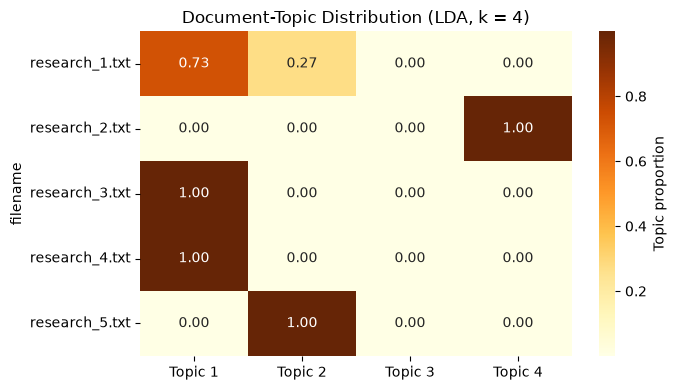

In [32]:
import seaborn as sns

fig, ax = plt.subplots(figsize = (7, 4))
sns.heatmap(doc_topic_data, annot = True, fmt = ".2f", cmap = "YlOrBr", cbar_kws = {"label": "Topic proportion"}, ax =ax)
ax.set_title("Document-Topic Distribution (LDA, k = 4)")
plt.tight_layout()
plt.show()                     

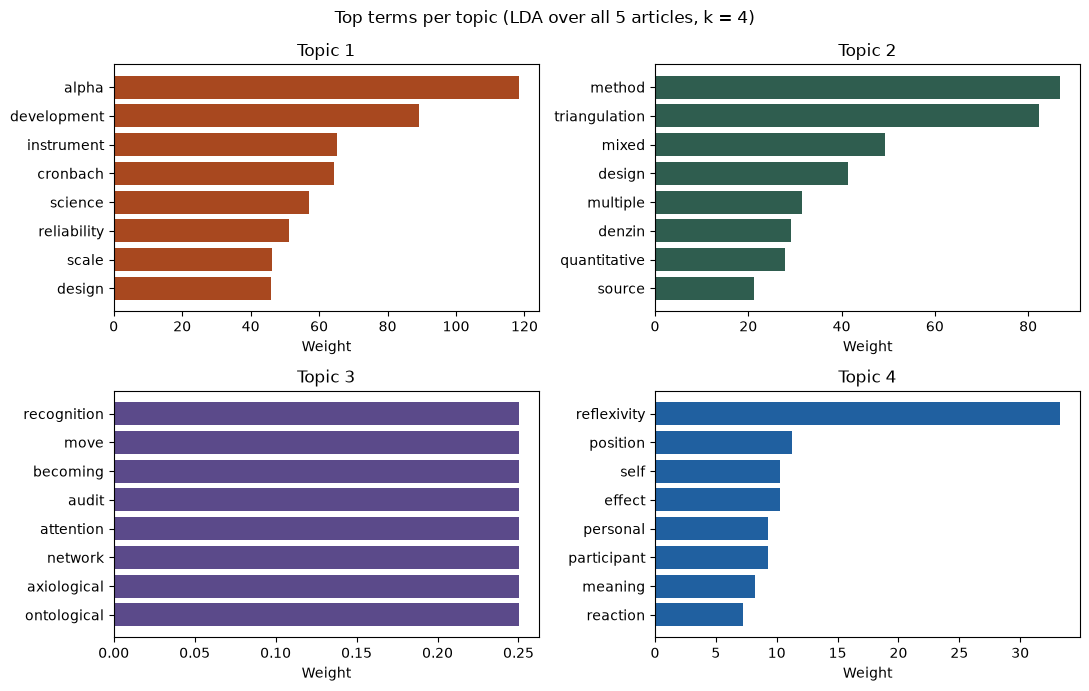

In [33]:
fig, axes = plt.subplots(2, 2, figsize = (11, 7))
colors = ["#a8481f", "#2f5d4f", "#5b4a8a", "#2060a0"]
for i, ax in enumerate(axes.flat):
    words = topic_word_lists[i][::-1]
    weights = topic_weight_lists[i][::-1]
    ax.barh(words, weights, color = colors[i])
    ax.set_title(f"Topic {i + 1}")
    ax.set_xlabel("Weight")
plt.suptitle("Top terms per topic (LDA over all 5 articles, k = 4)")
plt.tight_layout()
plt.show()

### 4.2

In [36]:
import pyLDAvis
import pyLDAvis.lda_model

panel = pyLDAvis.lda_model.prepare(lda, X_counts, count_vectorizer, mds = "tsne")
pyLDAvis.save_html(panel, "lda_vis.html")
print("saved interactive map to lda_vis.html")

panel

saved interactive map to lda_vis.html


PreparedData(topic_coordinates=                x           y  topics  cluster       Freq
topic                                                    
0      110.803604  -39.273762       1        1  65.178568
1       -1.484537   61.546577       2        1  23.829302
3     -102.400642  -50.472221       3        1  10.975843
2        9.718333 -150.793808       4        1   0.016286, topic_info=               Term        Freq       Total Category  logprob  loglift
1924  triangulation   65.000000   65.000000  Default  30.0000  30.0000
1169         method   76.000000   76.000000  Default  29.0000  29.0000
1193          mixed   39.000000   39.000000  Default  28.0000  28.0000
60            alpha  107.000000  107.000000  Default  27.0000  27.0000
1595    reflexivity   21.000000   21.000000  Default  26.0000  26.0000
...             ...         ...         ...      ...      ...      ...
1545      rationale    0.000626    3.025174   Topic4  -7.6009   0.2401
1548        reached    0.000626    3.0251